# 06 — CellFlow baseline on the PBMC subset (IL-15 held out)

Follows the CellFlow tutorial [Predicting donor-specific cytokine effects on PBMCs](https://cellflow.readthedocs.io/en/latest/notebooks/100_pbmc.html)
(`100_pbmc`) step by step, with the tutorial's argument names and values, on `data/pbmc_subset.h5ad`
(4 donors: Donor1, Donor2, Donor8, Donor12; 20 cytokines + PBS; built by `05_build_subset.ipynb`).

**Deviations from the tutorial**
* `method="rapids"` is dropped from `centered_pca` (rapids-singlecell is not in the `cellflow` env), so PCA runs with scanpy on CPU.
* `import rapids_singlecell as rsc` is dropped; the tutorial's UMAP and condition-embedding plots are not reproduced.
* Data is loaded from the subset file instead of `cellflow.datasets.pbmc_cytokines()`.
* Added: embedding sanity checks before training, wall time and peak GPU memory around `cf.train`, `cf.save()`,
  and evaluation per donor and per cell type against a control baseline.

**Held-out condition:** IL-15. It is kept in training for Donor8 only; IL-15 for Donor1, Donor2 and Donor12 is the test set (same split as the tutorial).

Kernel: `cellflow` (GPU node).

In [1]:
import warnings
from pandas.errors import SettingWithCopyWarning

warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", SettingWithCopyWarning)

import numpy as np
import pandas as pd
import seaborn as sns
import jax
import functools
import matplotlib.pyplot as plt
import anndata as ad
import scanpy as sc
import flax.linen as nn
import optax
import cellflow
from cellflow.model import CellFlow
import cellflow.preprocessing as cfpp
from cellflow.utils import match_linear
from cellflow.plotting import plot_condition_embedding
from cellflow.preprocessing import transfer_labels, compute_wknn, centered_pca, project_pca, reconstruct_pca
from cellflow.metrics import compute_r_squared, compute_e_distance

import os
import time
import scipy.sparse as sp

/fast/AG_Bunina/Pavel_1/miniforge3/envs/cellflow/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_PATH = "../data/pbmc_subset.h5ad"
MODEL_DIR = "../models"
MODEL_PREFIX = "06_baseline"
REQUIRE_GPU = True

import socket
print("host:", socket.gethostname(), "| SLURM_JOB_ID:", os.environ.get("SLURM_JOB_ID"))
print(jax.devices())
print(jax.devices()[0].device_kind)
if REQUIRE_GPU:
    assert jax.default_backend() == "gpu", (
        f"JAX sees no GPU ({jax.devices()}); this kernel is on a CPU-only node (e.g. the OOD session node max031). "
        "Run inside a GPU allocation: sbatch scripts/run_06_baseline.sbatch (see HARDWARE.md)."
    )

host: maxg11.mdc-berlin.net | SLURM_JOB_ID: 3374999


[CudaDevice(id=0)]
NVIDIA A40


## Data

In [3]:
adata = ad.read_h5ad(DATA_PATH)
adata

AnnData object with n_obs × n_vars = 1114081 × 2000
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type', 'cytokine_family'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'donor_embeddings', 'esm2_embeddings', 'hvg', 'log1p', 'subset_recipe'

In [4]:
adata.obs.head()

,sample,species,gene_count,tscp_count,mread_count,bc1_wind,bc2_wind,bc3_wind,bc1_well,bc2_well,...,log1p_n_genes_by_counts,log1p_total_counts,total_counts_MT,pct_counts_MT,log1p_total_counts_MT,donor,cytokine,treatment,cell_type,cytokine_family
66_107_008__s1,Donor12_ADSF,hg38,1184,1760,3369,66,107,8,F6,p2.A11,...,7.077498,7.473637,43.0,2.443182,3.784190,Donor12,ADSF,cytokine,CD4 Naive,Other
66_107_064__s1,Donor12_ADSF,hg38,1033,1376,2653,66,107,64,F6,p2.A11,...,6.941190,7.227663,37.0,2.688953,3.637586,Donor12,ADSF,cytokine,CD4 Memory,Other
66_107_100__s1,Donor12_ADSF,hg38,631,825,1598,66,107,100,F6,p2.A11,...,6.448889,6.716595,27.0,3.272727,3.332205,Donor12,ADSF,cytokine,CD4 Memory,Other
66_107_103__s1,Donor12_ADSF,hg38,1061,1439,2781,66,107,103,F6,p2.A11,...,6.967909,7.272399,22.0,1.528839,3.135494,Donor12,ADSF,cytokine,CD16 Mono,Other
66_107_107__s1,Donor12_ADSF,hg38,576,723,1398,66,107,107,F6,p2.A11,...,6.357842,6.584791,4.0,0.553250,1.609438,Donor12,ADSF,cytokine,CD16 Mono,Other


Is `.X` already log-normalised? Raw counts are non-negative integers with a max in the hundreds; log1p-normalised
values are non-integer with a max of roughly 5 to 10.

In [5]:
print(adata.X.max(), adata.X.min())

1823.0 0.0


In [6]:
X_head = adata.X[:1000]
X_head = X_head.toarray() if sp.issparse(X_head) else np.asarray(X_head)
print("integer-valued (first 1000 cells):", bool(np.allclose(X_head, np.round(X_head))))
print("library sizes (first 5 cells):", X_head.sum(axis=1)[:5])

integer-valued (first 1000 cells): True
library sizes (first 5 cells): [ 87.  88.  33. 158.  81.]


We first create a column which saves the experimental condition, i.e. the combination of donor and treatment,
and a boolean column which indicates if a cell is in control or perturbed state.

In [7]:
adata.obs["condition"] = adata.obs.apply(lambda x: x["donor"] + "_" + x["cytokine"], axis=1)
adata.obs["is_control"] = adata.obs.apply(lambda x: True if x["cytokine"]=="PBS" else False, axis=1)

We then normalize the data to a constant library size. (`.X` in the subset holds raw counts; scanpy may warn
"already log-transformed" only because `uns['log1p']` was carried over from the source file, as in the tutorial.)

In [8]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [9]:
print(adata.X.max(), adata.X.min())

8.938124 0.0


## Embedding checks (before training)

Checks on `uns['esm2_embeddings']` (cytokine representation) and `uns['donor_embeddings']` (donor representation).

Result of a pre-run check on the same file (CPU, 2026-09-27):
* `len(adata.uns['esm2_embeddings'])` = **93** (more than the 20 cytokines here, since the dict covers the full 90-cytokine dataset)
* embedding dimension = **2560** (ESM2)
* vector L2 norms: min **9.54**, median **12.77**, max **14.78**, so **not L2-normalised**
* obs cytokines missing from the dict: **`PBS` only**. This is expected: control cells are the source distribution
  and are never passed through the perturbation encoder, so PBS needs no embedding. All 20 treated cytokines are covered.
* `donor_embeddings`: 12 donors (all 4 subset donors present), dim 2000 (the control mean over the 2000 HVGs)

The cell below recomputes this at run time.

In [10]:
esm2 = adata.uns["esm2_embeddings"]
esm2_arr = {k: np.asarray(v) for k, v in esm2.items()}
esm2_dims = sorted({v.shape for v in esm2_arr.values()})
esm2_norms = pd.Series({k: float(np.linalg.norm(v)) for k, v in esm2_arr.items()}, name="l2_norm")

print("len(adata.uns['esm2_embeddings']):", len(esm2))
print("embedding dimension(s):", esm2_dims)
print("L2 norms:", esm2_norms.describe()[["min", "50%", "max"]].round(3).to_dict())
print("L2-normalised:", bool(np.allclose(esm2_norms.values, 1.0, atol=1e-3)))

obs_cytokines = set(adata.obs["cytokine"].unique())
missing = sorted(obs_cytokines - set(esm2))
print("obs cytokines missing from esm2_embeddings:", missing)
print("treated cytokines missing:", sorted(set(missing) - {"PBS"}))

donor_emb = adata.uns["donor_embeddings"]
print("donor_embeddings:", len(donor_emb), "entries, dim", {np.asarray(v).shape for v in donor_emb.values()})
print("obs donors missing from donor_embeddings:", sorted(set(adata.obs["donor"].unique()) - set(donor_emb)))

esm2_norms.loc[sorted(obs_cytokines - {"PBS"})].round(3).to_frame().T

len(adata.uns['esm2_embeddings']): 93
embedding dimension(s): [(2560,)]
L2 norms: {'min': 9.541, '50%': 12.774, 'max': 14.776}
L2-normalised: False
obs cytokines missing from esm2_embeddings: ['PBS']
treated cytokines missing: []
donor_embeddings: 12 entries, dim {(2000,)}
obs donors missing from donor_embeddings: []


,ADSF,BAFF,C5a,FGF-beta,GM-CSF,IFN-epsilon,IL-13,IL-15,IL-17B,IL-2,IL-20,IL-21,IL-31,IL-4,IL-6,IL-7,IL-9,LT-alpha2-beta1,SCF,TSLP
l2_norm,13.518,12.659,11.059,14.447,13.73,13.111,13.597,13.795,13.772,13.991,12.092,13.703,11.263,13.584,13.345,14.076,11.64,12.726,12.163,14.409


## Train / test split

As in the tutorial: IL-15 is observed during training for Donor8 only, and we predict the IL-15 response of the
remaining donors. The test data includes the control populations (PBS) of all donors.

In [11]:
adata_train = adata[(adata.obs["cytokine"]!="IL-15") | (adata.obs["donor"]=="Donor8")].copy()
adata_test = adata[((adata.obs["cytokine"]=="IL-15") & (adata.obs["donor"]!="Donor8")) | (adata.obs["cytokine"]=="PBS")].copy()
adata_train.n_obs, adata_test.n_obs

(1081229, 308067)

PCA on the training data, then project the test data onto it (tutorial uses `method="rapids"`; dropped here).

In [12]:
cfpp.centered_pca(adata_train, n_comps=100, keep_centered_data=False)
cfpp.project_pca(query_adata=adata_test, ref_adata=adata_train)

### PCA of the cells (training PCA space)

A 50k-cell subsample of the training data in the 100-PC space CellFlow is trained on, plus the projected test cells.

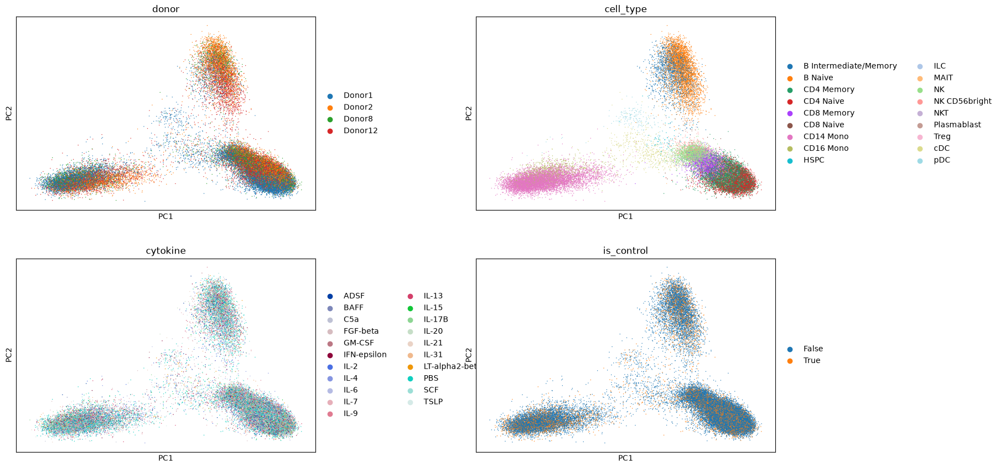

In [13]:
adata_train_plot = sc.pp.subsample(adata_train, n_obs=min(50_000, adata_train.n_obs), copy=True, random_state=0)
sc.pl.pca(adata_train_plot, color=["donor", "cell_type", "cytokine", "is_control"], ncols=2, size=4, wspace=0.4)

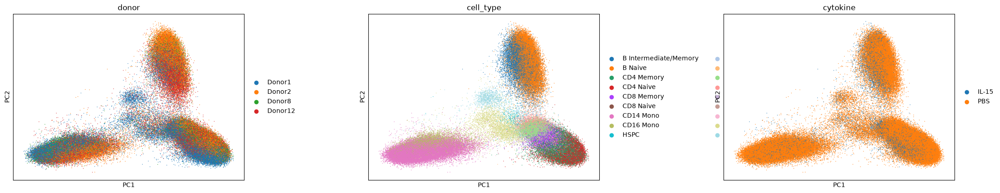

In [14]:
sc.pl.pca(adata_test, color=["donor", "cell_type", "cytokine"], ncols=3, size=4, wspace=0.4)

## Setting up the CellFlow model

In [15]:
cf = CellFlow(adata_train, solver="otfm")

## Preparing CellFlow's data handling with `prepare_data()`

In [16]:
adata.uns.keys()

dict_keys(['donor_embeddings', 'esm2_embeddings', 'hvg', 'log1p', 'subset_recipe'])

In [17]:
cf.prepare_data(
    sample_rep = "X_pca",
    control_key = "is_control",
    perturbation_covariates = {"cytokine_treatment": ("cytokine",)},
    perturbation_covariate_reps = {"cytokine_treatment": "esm2_embeddings"},
    sample_covariates = ["donor"],
    sample_covariate_reps = {"donor": "donor_embeddings"},
    split_covariates = ["donor"],
    max_combination_length = 1,
    null_value = 0.0,
)


[                                        ] | 0% Completed | 268.20 us


[########################################] | 100% Completed | 101.95 ms


[                                        ] | 0% Completed | 109.32 us


[##########                              ] | 25% Completed | 101.41 ms


[##########                              ] | 25% Completed | 201.84 ms


[###############                         ] | 38% Completed | 302.35 ms


[########################################] | 100% Completed | 402.83 ms


[                                        ] | 0% Completed | 154.55 us


[########################################] | 100% Completed | 101.81 ms

Subsample per condition for validation (1000 cells per train condition, 2000 per test condition), then prepare
validation data. `ad.concat` drops `.uns`, so the embeddings are copied back.

In [18]:
adatas_train_subsampled = []
for cond in adata_train.obs["condition"].unique():
    adatas_train_subsampled.append(sc.pp.subsample(adata_train[adata_train.obs["condition"]==cond], n_obs=1000, copy=True))

adata_train_for_validation = ad.concat(adatas_train_subsampled)

adatas_test_subsampled = []
for cond in adata_test.obs["condition"].unique():
    adatas_test_subsampled.append(sc.pp.subsample(adata_test[adata_test.obs["condition"]==cond], n_obs=2000, copy=True))

adata_test_for_validation = ad.concat(adatas_test_subsampled)

In [19]:
adata_train_for_validation.uns = adata_train.uns.copy()
adata_test_for_validation.uns = adata_test.uns.copy()

cf.prepare_validation_data(
    adata_train_for_validation,
    name="train",
    n_conditions_on_log_iteration=10,
    n_conditions_on_train_end=10,
)

cf.prepare_validation_data(
    adata_test_for_validation,
    name="test",
    n_conditions_on_log_iteration=None,
    n_conditions_on_train_end=None,
)


[                                        ] | 0% Completed | 187.45 us


[########################################] | 100% Completed | 101.55 ms


[                                        ] | 0% Completed | 104.26 us


[########################################] | 100% Completed | 101.83 ms


[                                        ] | 0% Completed | 124.52 us


[########################################] | 100% Completed | 102.06 ms

... (2 outputs left out)


[                                        ] | 0% Completed | 104.38 us


[########################################] | 100% Completed | 101.13 ms


[                                        ] | 0% Completed | 96.24 us


[########################################] | 100% Completed | 100.73 ms

## Preparing CellFlow's model architecture with `prepare_model()`

In [20]:
layers_before_pool = {
    "cytokine_treatment": {"layer_type": "mlp", "dims": [1024, 1024], "dropout_rate": 0.5},
    "donor": {"layer_type": "mlp", "dims": [256, 256], "dropout_rate": 0.0},
}

layers_after_pool = {
    "layer_type": "mlp", "dims": [1024, 1024], "dropout_rate": 0.0,
}

In [21]:
match_fn = functools.partial(match_linear, epsilon=0.5, tau_a=1.0, tau_b=1.0)

In [22]:
cf.prepare_model(
    condition_mode="deterministic",
    regularization=0.0,
    pooling="attention_token",
    pooling_kwargs={},
    layers_before_pool=layers_before_pool,
    layers_after_pool=layers_after_pool,
    condition_embedding_dim=256,
    cond_output_dropout=0.9,
    condition_encoder_kwargs={},
    pool_sample_covariates=True,
    time_freqs=1024,
    time_encoder_dims=[1024, 1024, 1024],
    time_encoder_dropout=0.0,
    hidden_dims=[2048, 2048, 2048],
    hidden_dropout=0.0,
    conditioning="concatenation",
    decoder_dims=[4096, 4096, 4096],
    vf_act_fn=nn.silu,
    vf_kwargs=None,
    probability_path={"constant_noise": 0.5},
    match_fn=match_fn,
    optimizer=optax.MultiSteps(optax.adam(5e-5), 20),
    solver_kwargs={},
    layer_norm_before_concatenation=False,
    linear_projection_before_concatenation=False,
)

## Metrics callbacks

As in the tutorial: metrics in PCA space plus R² decoded to gene space. The W&B logger is left out, as in the tutorial.

In [23]:
metrics_callback = cellflow.training.Metrics(metrics=["r_squared", "mmd", "e_distance"])
decoded_metrics_callback = cellflow.training.PCADecodedMetrics(ref_adata=adata_train, metrics=["r_squared"])

callbacks = [metrics_callback, decoded_metrics_callback]

## Training CellFlow

Tutorial settings (500k iterations, batch 1024, validation every 20k). Wall time is measured around `cf.train`.
Peak GPU memory is the JAX allocator's `peak_bytes_in_use` on device 0 over the whole process up to the end of
training. The kernel sets `XLA_PYTHON_CLIENT_PREALLOCATE=false`, so this reflects real use rather than the preallocated pool.

In [24]:
print("XLA_PYTHON_CLIENT_PREALLOCATE =", os.environ.get("XLA_PYTHON_CLIENT_PREALLOCATE"))

t0 = time.perf_counter()
cf.train(
        num_iterations=500_000,
        batch_size=1024,
        callbacks=callbacks,
        valid_freq=20_000,
    )
train_wall_s = time.perf_counter() - t0

mem_stats = jax.devices()[0].memory_stats() or {}
peak_gpu_gb = mem_stats.get("peak_bytes_in_use", float("nan")) / 1e9

print(f"wall time (cf.train): {train_wall_s:,.0f} s = {train_wall_s / 3600:.2f} h")
print(f"peak GPU memory (JAX, device 0): {peak_gpu_gb:.2f} GB")

XLA_PYTHON_CLIENT_PREALLOCATE = false



  0%|          | 0/500000 [00:00<?, ?it/s]


  0%|          | 1/500000 [00:14<2064:23:40, 14.86s/it]


  0%|          | 6/500000 [00:14<256:16:00,  1.85s/it] 


  0%|          | 11/500000 [00:15<115:21:25,  1.20it/s]


  0%|          | 16/500000 [00:15<65:34:09,  2.12it/s] 

... (100,044 outputs left out)


100%|█████████▉| 499992/500000 [3:48:32<00:00, 49.02it/s, loss=4.64]


100%|█████████▉| 499997/500000 [3:48:32<00:00, 49.06it/s, loss=4.64]


100%|██████████| 500000/500000 [3:48:33<00:00, 36.46it/s, loss=4.64]

wall time (cf.train): 13,832 s = 3.84 h
peak GPU memory (JAX, device 0): 3.07 GB


## Save the model

In [25]:
os.makedirs(MODEL_DIR, exist_ok=True)
cf.save(MODEL_DIR, file_prefix=MODEL_PREFIX, overwrite=True)

model_path = os.path.join(MODEL_DIR, f"{MODEL_PREFIX}_CellFlow.pkl")
print(os.path.abspath(model_path), f"{os.path.getsize(model_path) / 1e9:.2f} GB")

/fast/AG_Bunina/Pavel_1/cellflow-regen/models/06_baseline_CellFlow.pkl 2.52 GB


## Training statistics

In [26]:
cf.trainer.training_logs.keys()

dict_keys(['loss', 'train_r_squared_mean', 'test_r_squared_mean', 'train_mmd_mean', 'test_mmd_mean', 'train_e_distance_mean', 'test_e_distance_mean', 'pca_decoded_test_r_squared_mean', 'pca_decoded_train_r_squared_mean'])

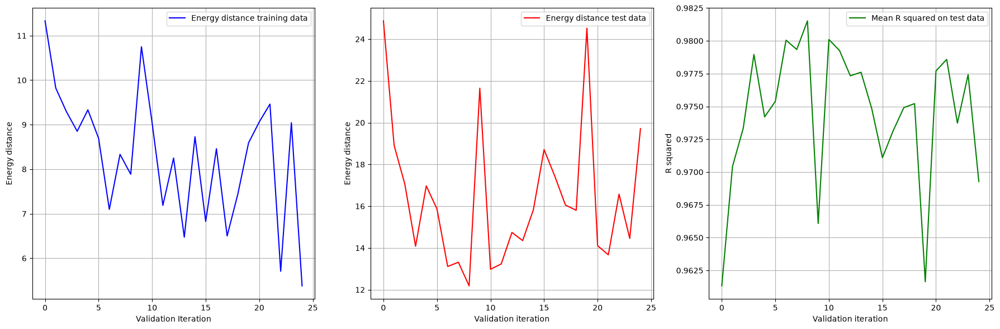

In [27]:
e_distances_train = cf.trainer.training_logs["train_e_distance_mean"]
e_distances_test = cf.trainer.training_logs["test_e_distance_mean"]
r_squared_test   = cf.trainer.training_logs["pca_decoded_test_r_squared_mean"]

iterations_train = np.arange(len(e_distances_train))
iterations_test  = np.arange(len(e_distances_test))
iterations_r2    = np.arange(len(r_squared_test))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].plot(iterations_train, e_distances_train, linestyle='-', color='blue', label='Energy distance training data')
axes[0].set_xlabel('Validation Iteration')
axes[0].set_ylabel('Energy distance')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(iterations_test, e_distances_test, linestyle='-', color='red', label='Energy distance test data')
axes[1].set_xlabel('Validation iteration')
axes[1].set_ylabel('Energy distance')
axes[1].legend()
axes[1].grid(True)

axes[2].plot(iterations_r2, r_squared_test, linestyle='-', color='green', label='Mean R squared on test data')
axes[2].set_xlabel('Validation iteration')
axes[2].set_ylabel('R squared')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

## Predicting held-out IL-15

As in the tutorial: predict IL-15 for the test donors, starting from the subsampled control cells (2000 per donor).

In [28]:
adata_ctrl_for_prediction = adata_test_for_validation[adata_test_for_validation.obs["is_control"].to_numpy()]
adata_ctrl_for_prediction.obs["condition"].unique()

['Donor12_PBS', 'Donor1_PBS', 'Donor2_PBS', 'Donor8_PBS']
Categories (4, object): ['Donor1_PBS', 'Donor2_PBS', 'Donor8_PBS', 'Donor12_PBS']

In [29]:
covariate_data_il15 = adata_test_for_validation[~adata_test_for_validation.obs["is_control"].to_numpy()].obs.drop_duplicates(subset=["condition"])
covariate_data_il15.head()

,sample,species,gene_count,tscp_count,mread_count,bc1_wind,bc2_wind,bc3_wind,bc1_well,bc2_well,...,total_counts_MT,pct_counts_MT,log1p_total_counts_MT,donor,cytokine,treatment,cell_type,cytokine_family,condition,is_control
11_192_045__s45,Donor12_IL-15,hg38,732,1047,2236,11,192,45,A11,p2.H12,...,61.0,5.826170,4.127134,Donor12,IL-15,cytokine,B Naive,Common γ chain/IL-13/TSLP,Donor12_IL-15,False
11_002_126__s118,Donor1_IL-15,hg38,2795,7518,13960,11,2,126,A11,A2,...,105.0,1.396648,4.663439,Donor1,IL-15,cytokine,CD4 Naive,Common γ chain/IL-13/TSLP,Donor1_IL-15,False
11_064_074__s56,Donor2_IL-15,hg38,2330,4459,9349,11,64,74,A11,F4,...,43.0,0.964342,3.784190,Donor2,IL-15,cytokine,CD4 Memory,Common γ chain/IL-13/TSLP,Donor2_IL-15,False


In [30]:
preds = cf.predict(adata=adata_ctrl_for_prediction, sample_rep="X_pca", condition_id_key="condition", covariate_data=covariate_data_il15)


[                                        ] | 0% Completed | 223.77 us


[########################################] | 100% Completed | 101.42 ms


[                                        ] | 0% Completed | 92.83 us


[########################################] | 100% Completed | 101.72 ms


[                                        ] | 0% Completed | 103.48 us


[########################################] | 100% Completed | 100.87 ms

In [31]:
adata_preds = []
for cond, array in preds.items():

    obs_data = pd.DataFrame({
        'condition': [cond] * array.shape[0]
    })
    adata_pred = ad.AnnData(X=np.empty((len(array),adata_train.n_vars)), obs=obs_data)
    adata_pred.obsm["X_pca"] = np.squeeze(array)
    adata_preds.append(adata_pred)

adata_preds = ad.concat(adata_preds)
adata_preds.var_names = adata_train.var_names

Transfer cell-type labels to the generated cells (1-NN on the training subsample), then decode PCA to gene space.

In [32]:
compute_wknn(ref_adata=adata_train_for_validation, query_adata=adata_preds, n_neighbors=1, ref_rep_key="X_pca", query_rep_key="X_pca")
transfer_labels(query_adata=adata_preds, ref_adata=adata_train_for_validation, label_key="cell_type")

INFO     cuML is not installed or GPU is not available. Falling back to neighborhood estimation using CPU with     
         pynndescent.                                                                                              


INFO     cuML is not installed or GPU is not available. Falling back to neighborhood estimation using CPU with     
         pynndescent.                                                                                              


In [33]:
reconstruct_pca(query_adata=adata_preds, use_rep="X_pca", ref_adata=adata_train, layers_key_added="X_recon")

adata_preds.obs["donor"] = adata_preds.obs.apply(lambda x: x["condition"].split("_")[0], axis=1)
adata_preds.obs["cytokine"] = adata_preds.obs.apply(lambda x: "_".join(x["condition"].split("_")[1:]), axis=1)
adata_preds.obs["cell_type"] = adata_preds.obs["cell_type_transfer"]
adata_preds.X = adata_preds.layers["X_recon"]
adata_preds

AnnData object with n_obs × n_vars = 6000 × 2000
    obs: 'condition', 'cell_type_transfer', 'cell_type_transfer_score', 'donor', 'cytokine', 'cell_type'
    obsm: 'X_pca'
    layers: 'X_recon'

### UMAP / PCA of generated vs true cells

As in the tutorial, with scanpy in place of `rsc`: concatenate generated cells, the training subsample and the true
IL-15 test cells, then recompute PCA, neighbours and UMAP on the joint object.

In [34]:
adata_preds.obs["mode"] = "generated"
adata_train_for_validation.obs["mode"] = "train"
adata_test_for_validation.obs["mode"] = "test"

adata_concatenated = ad.concat((adata_preds, adata_train_for_validation, adata_test_for_validation[~adata_test_for_validation.obs["is_control"].to_numpy()]))

sc.pp.pca(adata_concatenated)
sc.pp.neighbors(adata_concatenated)
sc.tl.umap(adata_concatenated)

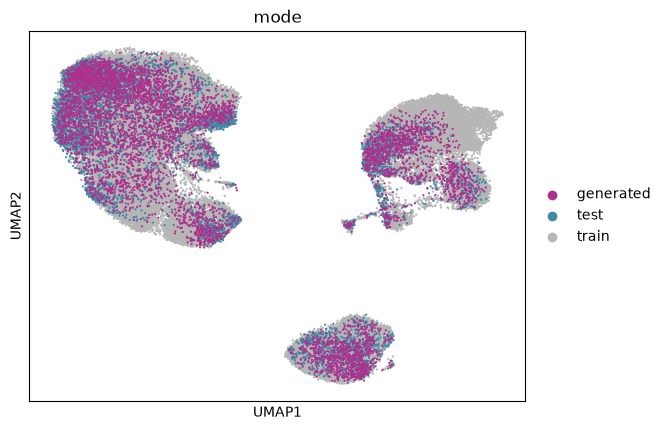

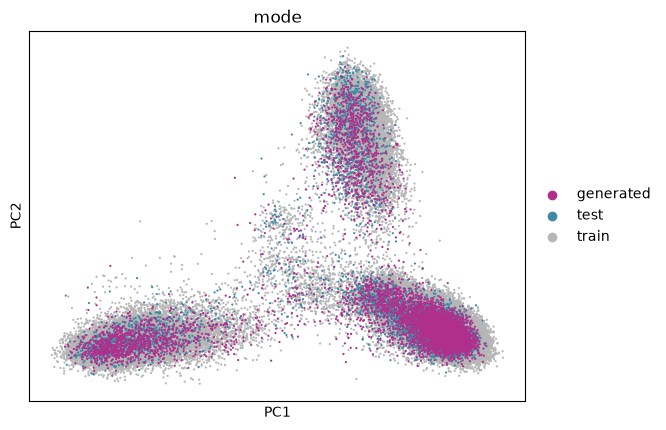

In [35]:
adata_concatenated.obs["condition_mode"] = adata_concatenated.obs.apply(lambda x: x["condition"] + "_" + x["mode"], axis=1)
adata_concatenated.obs.reset_index(inplace=True)

color_palette = {"generated": "#B12F8C", "test": "#3F8AA6", "train": "#B6B6B6"}
order = list(adata_concatenated[adata_concatenated.obs["mode"]=="train"].obs_names) + list(adata_concatenated[adata_concatenated.obs["mode"]=="test"].obs_names) + list(adata_concatenated[adata_concatenated.obs["mode"]=="generated"].obs_names)
sc.pl.umap(adata_concatenated[order], color=["mode"], palette=color_palette, size=10)
sc.pl.pca(adata_concatenated[order], color=["mode"], palette=color_palette, size=10)

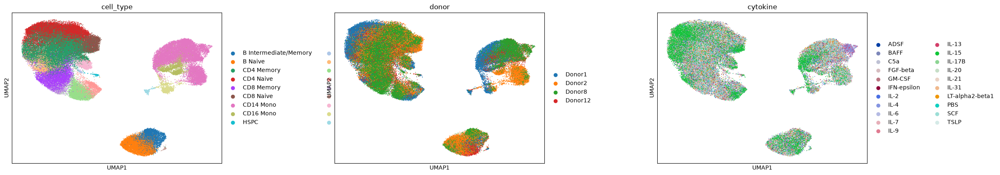

In [36]:
sc.pl.umap(adata_concatenated, color=["cell_type", "donor", "cytokine"], ncols=3, size=6, wspace=0.4)

Per held-out donor: generated IL-15 (magenta) should sit closer to true IL-15 (blue) than to that donor's
control cells (black).

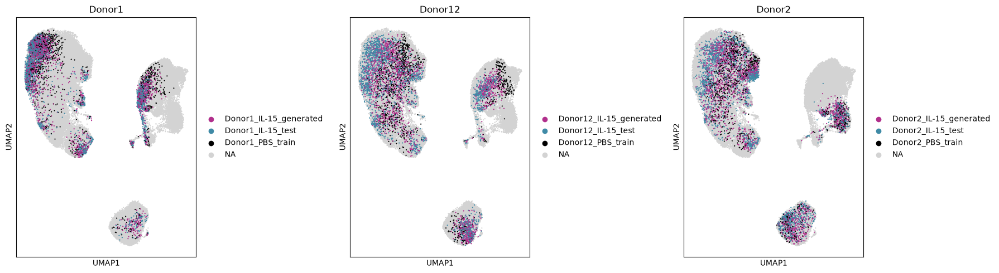

In [37]:
def plot_umap_highlight(adata, donor_id, ax):
    groups_to_visualize = [f"{donor_id}_PBS_train", f"{donor_id}_IL-15_test", f"{donor_id}_IL-15_generated"]

    # Define color palette
    color_palette = {k: "#B6B6B6" for k in adata.obs["condition_mode"].unique()}
    color_palette.update({
        f"{donor_id}_IL-15_generated": "#B12F8C",
        f"{donor_id}_IL-15_test": "#3F8AA6",
        f"{donor_id}_PBS_train": "#000000",
    })
    obs_to_highlight = list(adata[adata.obs["condition_mode"].isin(groups_to_visualize)].obs_names)
    np.random.shuffle(obs_to_highlight)
    order = list(adata[~adata.obs["condition_mode"].isin(groups_to_visualize)].obs_names) + \
            obs_to_highlight

    sc.pl.umap(
        adata[order],
        color="condition_mode",
        groups=groups_to_visualize,
        palette=color_palette,
        size=10,
        ax=ax,
        show=False,
        title=donor_id
    )

donors = sorted(adata_preds.obs["donor"].unique())
fig, axs = plt.subplots(1, len(donors), figsize=(6 * len(donors), 5))
axs = np.atleast_1d(axs).flatten()

for i, donor in enumerate(donors):
    plot_umap_highlight(adata_concatenated, donor, axs[i])

plt.tight_layout()
plt.show()

## Evaluation

As in the tutorial, distributional metrics use a 30-PC space fitted on a 100k-cell subsample of the entire dataset
(including test data), onto which true, generated and baseline cells are projected:
* `compute_e_distance(true, pred)` in that 30-PC space (lower is better)
* `compute_r_squared(true, pred)`: R² between the **mean** true and **mean** predicted log-normalised expression over the 2000 genes (higher is better)

**Control baseline:** the "prediction" for donor *d* is *d*'s own PBS cells, the same 2000 control cells fed to
CellFlow, unperturbed. Since `compute_r_squared` compares means, its R² is exactly the **control-mean baseline**.
For energy distance, the baseline is the control population itself.

Per cell type: true and control cells use their annotated `cell_type`; generated cells use the transferred label.
Groups with fewer than `MIN_CELLS` cells on any side are skipped.

In [38]:
adata_ref = sc.pp.subsample(adata, n_obs=100_000, copy=True)
cfpp.centered_pca(adata_ref, n_comps=30)

adata_true = adata_test_for_validation[~adata_test_for_validation.obs["is_control"].to_numpy()].copy()
adata_ctrl_baseline = adata_ctrl_for_prediction.copy()

cfpp.project_pca(query_adata=adata_preds, ref_adata=adata_ref)
cfpp.project_pca(query_adata=adata_true, ref_adata=adata_ref)
cfpp.project_pca(query_adata=adata_ctrl_baseline, ref_adata=adata_ref)

In [39]:
MIN_CELLS = 20


def _dense(X):
    return X.toarray() if sp.issparse(X) else np.asarray(X)


def evaluate(group_key=None):
    rows = []
    for cond in adata_preds.obs["condition"].unique():
        donor = cond.split("_")[0]
        true_c = adata_true[adata_true.obs["condition"] == cond]
        candidates = {
            "CellFlow": adata_preds[adata_preds.obs["condition"] == cond],
            "control_mean": adata_ctrl_baseline[adata_ctrl_baseline.obs["donor"] == donor],
        }
        groups = [None] if group_key is None else sorted(true_c.obs[group_key].astype(str).unique())
        for g in groups:
            t = true_c if g is None else true_c[true_c.obs[group_key].astype(str) == g]
            subsets = {m: (a if g is None else a[a.obs[group_key].astype(str) == g]) for m, a in candidates.items()}
            if min([t.n_obs] + [s.n_obs for s in subsets.values()]) < MIN_CELLS:
                continue
            t_X, t_pca = _dense(t.X), np.asarray(t.obsm["X_pca"])
            for model, s in subsets.items():
                rows.append({
                    "condition": cond,
                    "donor": donor,
                    "cell_type": "all" if g is None else g,
                    "model": model,
                    "n_true": t.n_obs,
                    "n_pred": s.n_obs,
                    "r_squared": float(compute_r_squared(t_X, _dense(s.X))),
                    "e_distance": float(compute_e_distance(t_pca, np.asarray(s.obsm["X_pca"]))),
                })
    return pd.DataFrame(rows)


df_donor = evaluate()
df_celltype = evaluate("cell_type")

### Per donor (held-out IL-15)

In [40]:
table_donor = df_donor.pivot_table(index="donor", columns="model", values=["r_squared", "e_distance"])
table_donor.loc["mean"] = table_donor.mean()
table_donor.round(4)

e_distance              r_squared             
model     CellFlow control_mean  CellFlow control_mean
donor                                                 
Donor1      7.2813      55.5059    0.9809       0.9165
Donor12    22.2032     166.5204    0.9469       0.7092
Donor2     20.0948      82.6986    0.9462       0.8380
mean       16.5264     101.5749    0.9580       0.8212

### Per donor × cell type

In [41]:
table_celltype = df_celltype.pivot_table(index=["donor", "cell_type"], columns="model", values=["r_squared", "e_distance"])
table_celltype["n_true"] = df_celltype.groupby(["donor", "cell_type"])["n_true"].first()
table_celltype.round(4)

e_distance              r_squared               \
model                           CellFlow control_mean  CellFlow control_mean   
donor   cell_type                                                              
Donor1  B Intermediate/Memory    12.3740      37.0873    0.9207       0.8972   
        B Naive                  14.0241      23.9946    0.9191       0.9252   
        CD14 Mono                21.4093     215.7236    0.9730       0.8988   
        CD16 Mono                13.4135     144.5275    0.9560       0.9054   
        CD4 Memory                8.9379      66.6975    0.9730       0.8953   
        CD4 Naive                10.8720      70.6187    0.9744       0.9119   
        CD8 Memory               26.0399     118.4208    0.9040       0.8011   
        CD8 Naive                25.5603      79.3101    0.8768       0.8023   
        MAIT                     23.2138      77.9927    0.9087       0.8581   
        NK                       24.5269      84.6139    0.8953       0.8428   
        NK CD56bright            32.8827     159.0406    0.8683       0.7612   
        Treg                     19.9167      71.3121    0.9191       0.8508   
        cDC                      35.8407     151.8492    0.9244       0.8723   
Donor12 B Intermediate/Memory    18.6238     103.4070    0.9284       0.8200   
        B Naive                   9.2401     105.4497    0.9283       0.8164   
        CD14 Mono                31.4173     424.0117    0.9642       0.8067   
        CD16 Mono               150.6897     486.0833    0.8991       0.7507   
        CD4 Memory               29.9471     188.1906    0.9260       0.6594   
        CD4 Naive                33.4890     252.6788    0.9428       0.6885   
        CD8 Memory               95.4154     315.6040    0.8153       0.5828   
        CD8 Naive                31.1780     190.2952    0.8785       0.6473   
        MAIT                     51.7378     213.5041    0.8391       0.6478   
        NK                       51.7458     256.2895    0.8297       0.6325   
        NK CD56bright            51.8685     282.6262    0.8481       0.6267   
        Treg                     79.1217     218.9532    0.8057       0.6158   
Donor2  B Intermediate/Memory    23.4352      28.2737    0.9561       0.9434   
        B Naive                  31.1342      17.9283    0.9614       0.9707   
        CD14 Mono                32.2805      58.9521    0.9537       0.9361   
        CD16 Mono                37.7272      76.9460    0.9169       0.9171   
        CD4 Memory               29.8901     133.3375    0.9148       0.7387   
        CD4 Naive                 8.0139     108.5771    0.9601       0.8437   
        CD8 Memory              110.8563     275.3117    0.7939       0.6236   
        CD8 Naive                50.2411     191.3755    0.8687       0.7011   
        MAIT                     85.3475     254.3350    0.7761       0.6358   
        NK                       25.9398     107.9089    0.8662       0.8023   
        NK CD56bright            58.2924     182.9085    0.8479       0.7414   
        Treg                     40.2255      87.0034    0.8854       0.7843   

                              n_true  
model                                 
donor   cell_type                     
Donor1  B Intermediate/Memory     34  
        B Naive                   47  
        CD14 Mono                337  
        CD16 Mono                 49  
        CD4 Memory               543  
        CD4 Naive                512  
        CD8 Memory                87  
        CD8 Naive                 49  
        MAIT                      49  
        NK                        59  
        NK CD56bright             56  
        Treg                      61  
        cDC                       79  
Donor12 B Intermediate/Memory     64  
        B Naive                  221  
        CD14 Mono                254  
        CD16 Mono                 42  
        CD4 Memory               512  
        CD

### Per cell type (mean over donors)

In [42]:
table_ct_mean = df_celltype.pivot_table(index="cell_type", columns="model", values=["r_squared", "e_distance"], aggfunc="mean")
table_ct_mean["cellflow_better_r2"] = table_ct_mean[("r_squared", "CellFlow")] > table_ct_mean[("r_squared", "control_mean")]
table_ct_mean["cellflow_better_edist"] = table_ct_mean[("e_distance", "CellFlow")] < table_ct_mean[("e_distance", "control_mean")]
table_ct_mean.round(4)

e_distance              r_squared               \
model                   CellFlow control_mean  CellFlow control_mean   
cell_type                                                              
B Intermediate/Memory    18.1444      56.2560    0.9351       0.8869   
B Naive                  18.1328      49.1242    0.9363       0.9041   
CD14 Mono                28.3691     232.8958    0.9636       0.8805   
CD16 Mono                67.2768     235.8523    0.9240       0.8577   
CD4 Memory               22.9251     129.4085    0.9379       0.7645   
CD4 Naive                17.4583     143.9582    0.9591       0.8147   
CD8 Memory               77.4372     236.4455    0.8377       0.6691   
CD8 Naive                35.6598     153.6603    0.8747       0.7169   
MAIT                     53.4330     181.9439    0.8413       0.7139   
NK                       34.0708     149.6041    0.8637       0.7592   
NK CD56bright            47.6812     208.1918    0.8547       0.7097   
Treg                     46.4213     125.7562    0.8701       0.7503   
cDC                      35.8407     151.8492    0.9244       0.8723   

                      cellflow_better_r2 cellflow_better_edist  
model                                                           
cell_type                                                       
B Intermediate/Memory               True                  True  
B Naive                             True                  True  
CD14 Mono                           True                  True  
CD16 Mono                           True                  True  
CD4 Memory                          True                  True  
CD4 Naive                           True                  True  
CD8 Memory                          True                  True  
CD8 Naive                           True                  True  
MAIT                                True                  True  
NK                                  True                  True  
NK CD56bright                       True                  True  
Treg                                True                  True  
cDC                                 True                  True

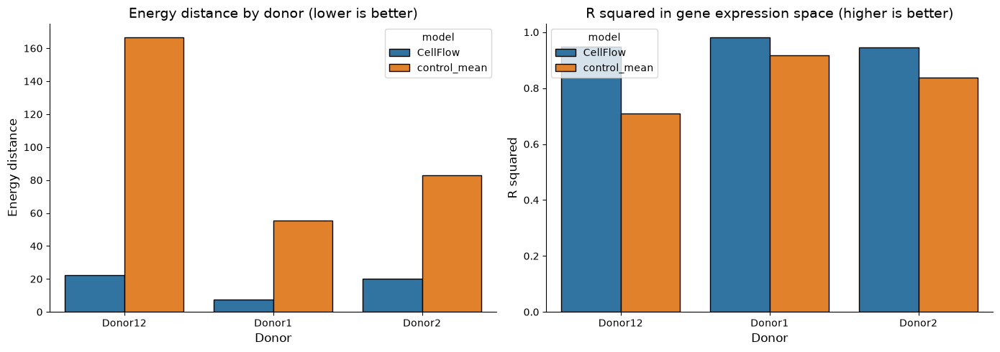

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

sns.barplot(data=df_donor, x="donor", y="e_distance", hue="model", edgecolor="black", ax=axes[0])
axes[0].set_title("Energy distance by donor (lower is better)", fontsize=14)
axes[0].set_xlabel("Donor", fontsize=12)
axes[0].set_ylabel("Energy distance", fontsize=12)

sns.barplot(data=df_donor, x="donor", y="r_squared", hue="model", edgecolor="black", ax=axes[1])
axes[1].set_title("R squared in gene expression space (higher is better)", fontsize=14)
axes[1].set_xlabel("Donor", fontsize=12)
axes[1].set_ylabel("R squared", fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

In [44]:
df_donor.to_csv(os.path.join(MODEL_DIR, f"{MODEL_PREFIX}_metrics_per_donor.csv"), index=False)
df_celltype.to_csv(os.path.join(MODEL_DIR, f"{MODEL_PREFIX}_metrics_per_celltype.csv"), index=False)

## Acceptance: CellFlow vs control-mean on held-out IL-15

CellFlow passes if, averaged over the held-out donors, it has **higher R²** and **lower energy distance** than
the control baseline. Per-donor wins are listed alongside.

In [45]:
wide = df_donor.pivot_table(index="donor", columns="model", values=["r_squared", "e_distance"])
r2_wins = int((wide[("r_squared", "CellFlow")] > wide[("r_squared", "control_mean")]).sum())
ed_wins = int((wide[("e_distance", "CellFlow")] < wide[("e_distance", "control_mean")]).sum())
mean = wide.mean()
r2_ok = mean[("r_squared", "CellFlow")] > mean[("r_squared", "control_mean")]
ed_ok = mean[("e_distance", "CellFlow")] < mean[("e_distance", "control_mean")]

print(f"R²:          CellFlow {mean[('r_squared', 'CellFlow')]:.4f} vs control-mean {mean[('r_squared', 'control_mean')]:.4f}"
      f"  -> CellFlow better in {r2_wins}/{len(wide)} donors")
print(f"E-distance:  CellFlow {mean[('e_distance', 'CellFlow')]:.4f} vs control {mean[('e_distance', 'control_mean')]:.4f}"
      f"  -> CellFlow better in {ed_wins}/{len(wide)} donors")
print("ACCEPTANCE:", "PASS" if (r2_ok and ed_ok) else "FAIL")

R²:          CellFlow 0.9580 vs control-mean 0.8212  -> CellFlow better in 3/3 donors
E-distance:  CellFlow 16.5264 vs control 101.5749  -> CellFlow better in 3/3 donors
ACCEPTANCE: PASS


## Run record

In [46]:
run_record = {
    "gpu": jax.devices()[0].device_kind,
    "n_train_cells": adata_train.n_obs,
    "n_test_cells": adata_test.n_obs,
    "num_iterations": 500_000,
    "train_wall_time_h": round(train_wall_s / 3600, 3),
    "peak_gpu_memory_gb": round(peak_gpu_gb, 2),
    "model_path": os.path.abspath(model_path),
    "mean_r2_cellflow": round(float(mean[("r_squared", "CellFlow")]), 4),
    "mean_r2_control_mean": round(float(mean[("r_squared", "control_mean")]), 4),
    "mean_edist_cellflow": round(float(mean[("e_distance", "CellFlow")]), 4),
    "mean_edist_control": round(float(mean[("e_distance", "control_mean")]), 4),
    "acceptance": "PASS" if (r2_ok and ed_ok) else "FAIL",
}
pd.Series(run_record).to_frame("value")

,value
gpu,NVIDIA A40
n_train_cells,1081229
n_test_cells,308067
num_iterations,500000
train_wall_time_h,3.842
peak_gpu_memory_gb,3.07
model_path,/fast/AG_Bunina/Pavel_1/cellflow-regen/models/...
mean_r2_cellflow,0.958
mean_r2_control_mean,0.8212
mean_edist_cellflow,16.5264


In [1]:
import pickle, os
with open("../models/06_baseline_CellFlow.pkl","rb") as f:
    obj = pickle.load(f)
print(obj.train_data.cell_data.shape, obj.train_data.cell_data.dtype)

/fast/AG_Bunina/Pavel_1/miniforge3/envs/cellflow/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/fast/AG_Bunina/Pavel_1/miniforge3/envs/cellflow/lib/python3.11/site-packages/jax/_src/xla_bridge.py", line 508, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/fast/AG_Bunina/Pavel_1/miniforge3/envs/cellflow/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 370, in initialize
    _check_cuda_versions(raise_on_first_error = True)
  File "/fast/AG_Bunina/Pavel_1/miniforge3/envs/cellflow/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 274, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
  

(1081229, 100) float32
